# 🧠 LeNet-5 Architecture: Complete Implementation using Keras
### 📖 Comprehensive Tutorial with Hinglish Explanation & Mathematical Details

---

## 📌 1. LeNet-5 Kya Hai? (Introduction)

**LeNet-5** computer vision aur deep learning ki duniya ka ek iconic aur historical Convolutional Neural Network (CNN) architecture hai. 
- **Kisne banaya?**: Isko **Yann LeCun, Léon Bottou, Yoshua Bengio, aur Patrick Haffner** ne **1998** mein introduce kiya tha.
- **Research Paper**: *"Gradient-Based Learning Applied to Document Recognition"*
- **Purpose**: Iska main use bank checks par likhe handwritten digits aur postal zip codes ko automatically identify aur classify karna tha.
- **Importance**: Is architecture ne prove kiya tha ki manual feature extraction (jaise Sobel filter, HOG, etc.) ki jagah ek neural network raw pixels se automatically hierarchical features (edges $\rightarrow$ textures $\rightarrow$ shapes) learn kar sakta hai.

---

## 📐 2. LeNet-5 Architecture Overview (Layer by Layer)

Original LeNet-5 architecture mein **7 trainable layers** hoti hain (Input layer ko count nahi karte):
1. **Input**: $32 \times 32 \times 1$ Grayscale Image
2. **C1 (Convolutional Layer)**: 6 filters of size $5 \times 5$, Stride = 1, Padding = 'valid' $\rightarrow$ Output: $28 \times 28 \times 6$
3. **S2 (Subsampling / Average Pooling)**: $2 \times 2$ pool size, Stride = 2 $\rightarrow$ Output: $14 \times 14 \times 6$
4. **C3 (Convolutional Layer)**: 16 filters of size $5 \times 5$, Stride = 1, Padding = 'valid' $\rightarrow$ Output: $10 \times 10 \times 16$
5. **S4 (Subsampling / Average Pooling)**: $2 \times 2$ pool size, Stride = 2 $\rightarrow$ Output: $5 \times 5 \times 16$
6. **C5 (Convolutional Layer)**: 120 filters of size $5 \times 5$, Stride = 1, Padding = 'valid' $\rightarrow$ Output: $1 \times 1 \times 120$
7. **Flattening**: $1 \times 1 \times 120 \rightarrow 120$ 1D Vector
8. **F6 (Fully Connected Layer)**: 84 neurons with Tanh activation
9. **Output Layer**: 10 neurons (Digits 0 se 9 tak) with Softmax activation (Original paper mein Euclidean RBF tha)

### 📊 Layer Summary Table:

| Layer Name | Type | Number of Filters / Units | Filter Size | Stride | Padding | Activation | Output Shape | Parameters Formula | Trainable Params |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Input** | Image | - | - | - | - | - | `(32, 32, 1)` | - | 0 |
| **C1** | Conv2D | 6 | $5 \times 5$ | 1 | Valid | Tanh / ReLU | `(28, 28, 6)` | $(5 \times 5 \times 1 + 1) \times 6$ | **156** |
| **S2** | AvgPool / MaxPool | - | $2 \times 2$ | 2 | Valid | - | `(14, 14, 6)` | None (Modern) | **0** |
| **C3** | Conv2D | 16 | $5 \times 5$ | 1 | Valid | Tanh / ReLU | `(10, 10, 16)` | $(5 \times 5 \times 6 + 1) \times 16$ | **2,416** |
| **S4** | AvgPool / MaxPool | - | $2 \times 2$ | 2 | Valid | - | `(5, 5, 16)` | None (Modern) | **0** |
| **C5** | Conv2D / Dense | 120 | $5 \times 5$ | 1 | Valid | Tanh / ReLU | `(1, 1, 120)` | $(5 \times 5 \times 16 + 1) \times 120$ | **48,120** |
| **Flatten** | Reshape | - | - | - | - | - | `(120,)` | - | **0** |
| **F6** | Dense (FC) | 84 | - | - | - | Tanh / ReLU | `(84,)` | $(120 + 1) \times 84$ | **10,164** |
| **Output** | Dense (FC) | 10 | - | - | - | Softmax | `(10,)` | $(84 + 1) \times 10$ | **850** |
| **Total** | | | | | | | | | **~61,706** |

---

### 🔢 Important Formulas (Kaise calculate hota hai?):
1. **Output Dimension of Convolution / Pooling**:
   $$\text{Output Size} = \left\lfloor \frac{W - F + 2P}{S} \right\rfloor + 1$$
   - $W$ = Input width/height
   - $F$ = Filter (Kernel) size
   - $P$ = Padding
   - $S$ = Stride
2. **Trainable Parameters in Conv2D**:
   $$\text{Params} = (F_w \times F_h \times C_{in} + 1) \times C_{out}$$
   *(Jahan $+1$ har filter ka bias hai)*


In [1]:
# ============================================================
# STEP 1: Zaroori Libraries Import Kar Rahe Hain
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

# Setting random seeds taaki har baar same reproducible results milein
np.random.seed(42)
tf.random.set_seed(42)

print(f"✅ TensorFlow Version: {tf.__version__}")
print(f"✅ Keras Version: {keras.__version__}")

# Check karte hain ki GPU available hai ya CPU par run ho raha hai
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"🚀 GPU Available: {gpu_devices}")
else:
    print("ℹ️ Running on CPU (LeNet-5 lightweight hai, CPU par bhi bahut fast chalega!)")


✅ TensorFlow Version: 2.21.0
✅ Keras Version: 3.13.2
ℹ️ Running on CPU (LeNet-5 lightweight hai, CPU par bhi bahut fast chalega!)


In [2]:
# ============================================================
# STEP 2: MNIST Dataset Load Karna
# ============================================================

# MNIST dataset me 70,000 handwritten digits (0 se 9) ki grayscale images hoti hain
# 60,000 images training ke liye aur 10,000 testing ke liye
mnist = keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print(f"📦 X_train shape: {X_train.shape} | Labels: {y_train.shape}")
print(f"📦 X_test shape:  {X_test.shape}  | Labels: {y_test.shape}")
print(f"🔢 Total Classes: {len(np.unique(y_train))} (Digits: {np.unique(y_train)})")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
📦 X_train shape: (60000, 28, 28) | Labels: (60000,)
📦 X_test shape:  (10000, 28, 28)  | Labels: (10000,)
🔢 Total Classes: 10 (Digits: [0 1 2 3 4 5 6 7 8 9])


### 💡 Hinglish Explanation: MNIST Dataset ki details
- Har image ka size `28 x 28` pixels hai.
- Har pixel ki value `0 se 255` hoti hai (0 = Black background, 255 = White stroke).
- `y_train` aur `y_test` me actual digit label (0 to 9) stored hai.

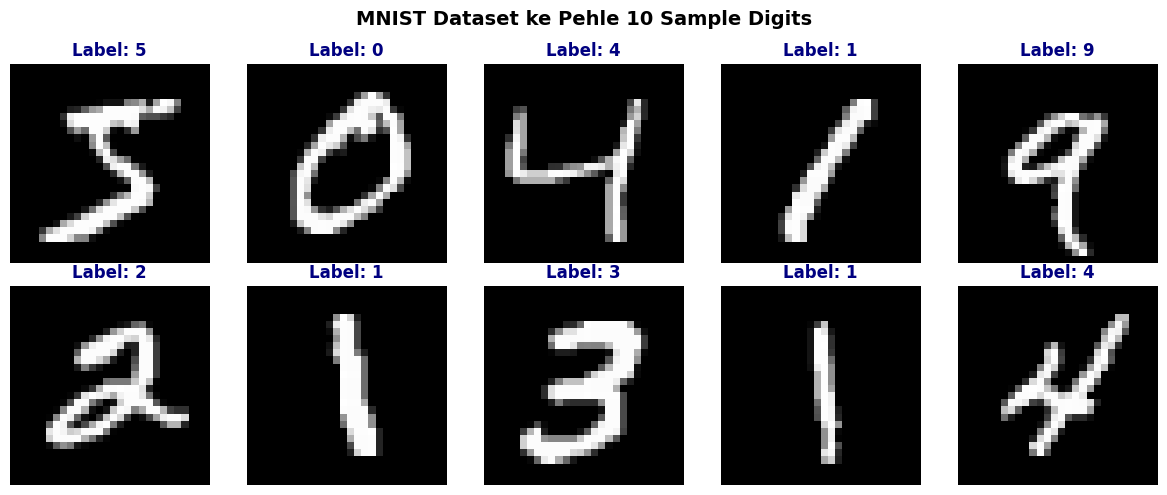

In [3]:
# ============================================================
# STEP 2.1: Dataset ke Sample Digits ko Visualise Karna
# ============================================================

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}", fontsize=12, fontweight='bold', color='navy')
    plt.axis('off')

plt.suptitle("MNIST Dataset ke Pehle 10 Sample Digits", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 🛠️ STEP 3: Data Preprocessing & Zero-Padding (28x28 $\rightarrow$ 32x32)

Yahan 3 zaroori steps perform karne hain:

1. **Normalization**:
   - Pixel values $0$ se $255$ ke beech hoti hain. Unhe $255.0$ se divide karke $[0.0, 1.0]$ float range me convert karenge.
   - *Kyun karte hain?* Normalization se Gradient Descent smoothly aur fast converge hota hai, aur weights blast nahi hote.

2. **Channel Dimension Add Karna**:
   - CNN layers $4D$ tensor expect karti hain: `(batch_size, height, width, channels)`.
   - Grayscale images mein 1 single channel hota hai, isliye shape `(N, 28, 28)` se `(N, 28, 28, 1)` banate hain.

3. **Zero Padding (28x28 $\rightarrow$ 32x32) - Bahut Zaroori Point!**:
   - Original LeNet-5 architecture ka input size **$32 \times 32$** expect karta hai.
   - MNIST images ka size **$28 \times 28$** hai.
   - Agar hum bina pad kiye $28 \times 28$ denge, toh:
     - C1: $(28 - 5 + 1) = 24$
     - S2: $24 / 2 = 12$
     - C3: $(12 - 5 + 1) = 8$
     - S4: $8 / 2 = 4$
     - C5: $(4 - 5 + 1) = 0$ (Negative/Invalid filter convolution!)
   - Isliye hum image ke chaaron taraf (top, bottom, left, right) **2-2 pixels ka zero padding** add karte hain:
     - New Height = $2 + 28 + 2 = 32$
     - New Width = $2 + 28 + 2 = 32$

In [4]:
# ============================================================
# STEP 3: Preprocessing & Padding Implement Karna
# ============================================================

# 1. Normalization: 0 se 1 ke range me lana
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# 2. Reshape: Grayscale channel (1) add karna
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

# 3. Zero-Padding: 28x28 ko 32x32 banana
# np.pad me ((samples_pad), (height_pad), (width_pad), (channels_pad))
# Height me top=2, bottom=2; Width me left=2, right=2
X_train_padded = np.pad(X_train, ((0, 0), (2, 2), (2, 2), (0, 0)), mode='constant')
X_test_padded = np.pad(X_test, ((0, 0), (2, 2), (2, 2), (0, 0)), mode='constant')

print("Preprocessing ke baad naye shapes:")
print(f"X_train_padded: {X_train_padded.shape}")
print(f"X_test_padded:  {X_test_padded.shape}")
print(f"Pixel values range: min={X_train_padded.min():.1f}, max={X_train_padded.max():.1f}")


Preprocessing ke baad naye shapes:
X_train_padded: (60000, 32, 32, 1)
X_test_padded:  (10000, 32, 32, 1)
Pixel values range: min=0.0, max=1.0


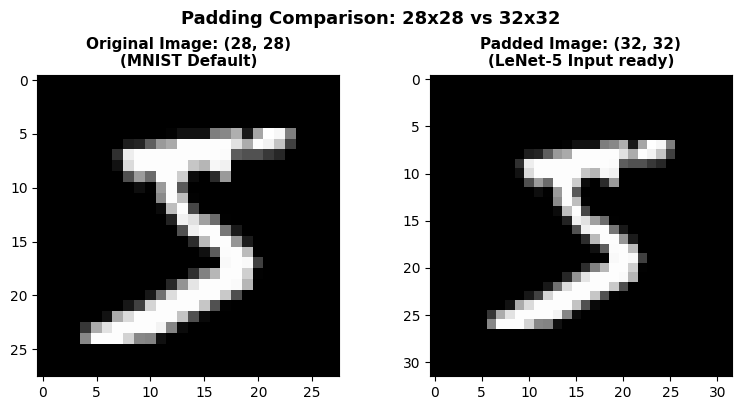

In [5]:
# Original 28x28 aur Padded 32x32 image ka side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(X_train[0].squeeze(), cmap='gray')
axes[0].set_title(f"Original Image: {X_train[0].shape[:2]}\n(MNIST Default)", fontsize=11, fontweight='bold')
axes[0].axis('on')

axes[1].imshow(X_train_padded[0].squeeze(), cmap='gray')
axes[1].set_title(f"Padded Image: {X_train_padded[0].shape[:2]}\n(LeNet-5 Input ready)", fontsize=11, fontweight='bold')
axes[1].axis('on')

plt.suptitle("Padding Comparison: 28x28 vs 32x32", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 🏗️ STEP 4: Classical LeNet-5 Architecture Build Karna

Original 1998 LeNet-5 paper ki key specifications:
- **Activation Function**: `tanh` (Hyperbolic tangent) use hoti thi.
- **Subsampling (Pooling)**: `AveragePooling2D` use hoti thi.
- **Output Layer**: 10 units with `softmax` (Modern probabilistic classification standard).

Ab hum Keras ke `Sequential` API ka use karke is exact architecture ko code karenge.

In [6]:
# ============================================================
# STEP 4: Classical LeNet-5 Architecture (Keras Implementation)
# ============================================================

def build_lenet5_classic(input_shape=(32, 32, 1), num_classes=10):
    """
    Classical LeNet-5 Model:
    - Input: 32x32x1 grayscale image
    - Activations: Tanh
    - Pooling: AveragePooling2D (2x2, stride=2)
    - Output: Softmax (10 classes)
    """
    model = models.Sequential([
        # -------------------------------------------------------------
        # 1. Layer C1 (Convolutional Layer)
        # Input: (32, 32, 1)
        # 6 filters of size 5x5, stride=1, padding='valid'
        # Output Feature Map Size: (32 - 5)/1 + 1 = 28 -> (28, 28, 6)
        # Parameters: (5 * 5 * 1 + 1) * 6 = 156
        # -------------------------------------------------------------
        layers.Conv2D(filters=6, kernel_size=(5, 5), strides=(1, 1),
                      activation='tanh', padding='valid',
                      input_shape=input_shape, name='C1_Conv'),

        # -------------------------------------------------------------
        # 2. Layer S2 (Subsampling / Average Pooling Layer)
        # Pool size: 2x2, stride=2, padding='valid'
        # Output Size: 28 / 2 = 14 -> (14, 14, 6)
        # Parameters: 0 (Modern Keras implementation)
        # -------------------------------------------------------------
        layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2),
                               padding='valid', name='S2_AvgPool'),

        # -------------------------------------------------------------
        # 3. Layer C3 (Convolutional Layer)
        # 16 filters of size 5x5, stride=1, padding='valid'
        # Output Feature Map Size: (14 - 5)/1 + 1 = 10 -> (10, 10, 16)
        # Parameters: (5 * 5 * 6 + 1) * 16 = 2,416
        # -------------------------------------------------------------
        layers.Conv2D(filters=16, kernel_size=(5, 5), strides=(1, 1),
                      activation='tanh', padding='valid', name='C3_Conv'),

        # -------------------------------------------------------------
        # 4. Layer S4 (Subsampling / Average Pooling Layer)
        # Pool size: 2x2, stride=2, padding='valid'
        # Output Size: 10 / 2 = 5 -> (5, 5, 16)
        # Parameters: 0
        # -------------------------------------------------------------
        layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2),
                               padding='valid', name='S4_AvgPool'),

        # -------------------------------------------------------------
        # 5. Layer C5 (Convolutional Layer)
        # 120 filters of size 5x5, stride=1, padding='valid'
        # Output Size: (5 - 5)/1 + 1 = 1 -> (1, 1, 120)
        # Parameters: (5 * 5 * 16 + 1) * 120 = 48,120
        # -------------------------------------------------------------
        layers.Conv2D(filters=120, kernel_size=(5, 5), strides=(1, 1),
                      activation='tanh', padding='valid', name='C5_Conv'),

        # -------------------------------------------------------------
        # Flattening Layer: (1, 1, 120) 3D tensor ko 120 1D vector me flatten karna
        # -------------------------------------------------------------
        layers.Flatten(name='Flatten'),

        # -------------------------------------------------------------
        # 6. Layer F6 (Fully Connected / Dense Layer)
        # 84 neurons, activation='tanh'
        # Parameters: (120 input units + 1 bias) * 84 = 10,164
        # -------------------------------------------------------------
        layers.Dense(units=84, activation='tanh', name='F6_Dense'),

        # -------------------------------------------------------------
        # 7. Output Layer (Dense Layer)
        # 10 neurons (Digits 0-9), activation='softmax'
        # Parameters: (84 input units + 1 bias) * 10 = 850
        # -------------------------------------------------------------
        layers.Dense(units=num_classes, activation='softmax', name='Output_Layer')
    ], name="Classic_LeNet_5")

    return model

# Model instantiate karte hain
model_classic = build_lenet5_classic()
model_classic.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Classic_LeNet_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ C1_Conv (Conv2D)                │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2_AvgPool (AveragePooling2D)   │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3_Conv (Conv2D)                │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4_AvgPool (AveragePooling2D)   │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5_Conv (Conv2D)                │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6_Dense (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

### 🧮 Detailed Parameter Calculations (Manual Verification):

Aaiye dekhte hain ki summary mein total **61,706** parameters kaise aaye:

1. **C1_Conv**:
   - Filter size = $5 \times 5$
   - Input channels = $1$ (Grayscale)
   - Number of filters = $6$
   - Formula: $[(5 \times 5 \times 1) + 1 \text{ (bias)}] \times 6 = 26 \times 6 =$ **156**

2. **S2_AvgPool**:
   - Average pooling mein non-learnable pooling hoti hai, isliye learnable parameters = **0**

3. **C3_Conv**:
   - Filter size = $5 \times 5$
   - Input channels = $6$ (C1 ke outputs)
   - Number of filters = $16$
   - Formula: $[(5 \times 5 \times 6) + 1 \text{ (bias)}] \times 16 = [150 + 1] \times 16 = 151 \times 16 =$ **2,416**

4. **S4_AvgPool**:
   - Parameters = **0**

5. **C5_Conv**:
   - Filter size = $5 \times 5$
   - Input channels = $16$
   - Number of filters = $120$
   - Formula: $[(5 \times 5 \times 16) + 1 \text{ (bias)}] \times 120 = [400 + 1] \times 120 = 401 \times 120 =$ **48,120**

6. **F6_Dense**:
   - Inputs = $120$
   - Outputs = $84$
   - Formula: $(120 \text{ weights} + 1 \text{ bias}) \times 84 = 121 \times 84 =$ **10,164**

7. **Output_Layer**:
   - Inputs = $84$
   - Outputs = $10$
   - Formula: $(84 \text{ weights} + 1 \text{ bias}) \times 10 = 85 \times 10 =$ **850**

$$\text{Total Parameters} = 156 + 2,416 + 48,120 + 10,164 + 850 = \mathbf{61,706}$$
Har calculation bilkul exact match karti hai!

In [7]:
# ============================================================
# STEP 5: Model Compile Karna
# ============================================================

# - Optimizer: Adam (Learning rate = 0.001) fast convergence ke liye
# - Loss: Sparse Categorical Crossentropy (kyunki labels 0 se 9 single integer values hain)
# - Metric: Accuracy (kitne percent digits sahi predict hue)

model_classic.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ Model successfully compile ho gaya hai!")


✅ Model successfully compile ho gaya hai!


## 🏃 STEP 6: Model Training (Fit) with Callbacks

Training ke dauran hum kuch best practices follow karenge:
- **Batch Size (128)**: 128 images ka ek batch forward aur backward pass karega.
- **Epochs (12)**: Model poore dataset ko 12 baar dekhega.
- **Validation Split (0.2)**: 60,000 images mein se 20% (12,000 images) alag rakhenge validation ke liye taaki overfitting check kar sakein.
- **EarlyStopping Callback**: Agar validation loss 3 epochs tak improve nahi hua, toh training automatically ruk jayegi aur best weights restore ho jayenge.

In [8]:
# ============================================================
# STEP 6: Training with EarlyStopping Callback
# ============================================================

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Model train karte hain
history_classic = model_classic.fit(
    X_train_padded, y_train,
    batch_size=128,
    epochs=12,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/12
375/375 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.8890 - loss: 0.3809 - val_accuracy: 0.9477 - val_loss: 0.1755
Epoch 2/12
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 70ms/step - accuracy: 0.9544 - loss: 0.1471 - val_accuracy: 0.9647 - val_loss: 0.1184
Epoch 3/12
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 72ms/step - accuracy: 0.9705 - loss: 0.0984 - val_accuracy: 0.9731 - val_loss: 0.0889
Epoch 4/12
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 73ms/step - accuracy: 0.9778 - loss: 0.0732 - val_accuracy: 0.9760 - val_loss: 0.0755
Epoch 5/12
375/375 ━━━━━━━━━━━━━━━━━━━━ 54s 143ms/step - accuracy: 0.9827 - loss: 0.0575 - val_accuracy: 0.9790 - val_loss: 0.0686
Epoch 6/12
375/375 ━━━━━━━━━━━━━━━━━━━━ 74s 123ms/step - accuracy: 0.9869 - loss: 0.0463 - val_accuracy: 0.9808 - val_loss: 0.0654
Epoch 7/12
375/375 ━━━━━━━━━━━━━━━━━━━━ 56s 148ms/step - accuracy: 0.9892 - loss: 0.0378 - val_accuracy: 0.9818 - val_loss: 0.0633
Epoch 8/12
375/375 ━━━━━━━━━━━━━━━━━━━━ 56s 150ms/step - accuracy: 0.9914 - loss: 0.030

## 📈 STEP 7: Training vs Validation Learning Curves

Training history se hum Loss aur Accuracy plot karenge:
- **Loss Plot**: Training aur Validation loss dono smoothly neeche jaane chahiye.
- **Accuracy Plot**: Dono curves upar jaane chahiye aur close hone chahiye. Agar Training accuracy 99% ho aur Validation accuracy 90% par atak jaye, toh iska matlab model *overfitting* kar raha hai.

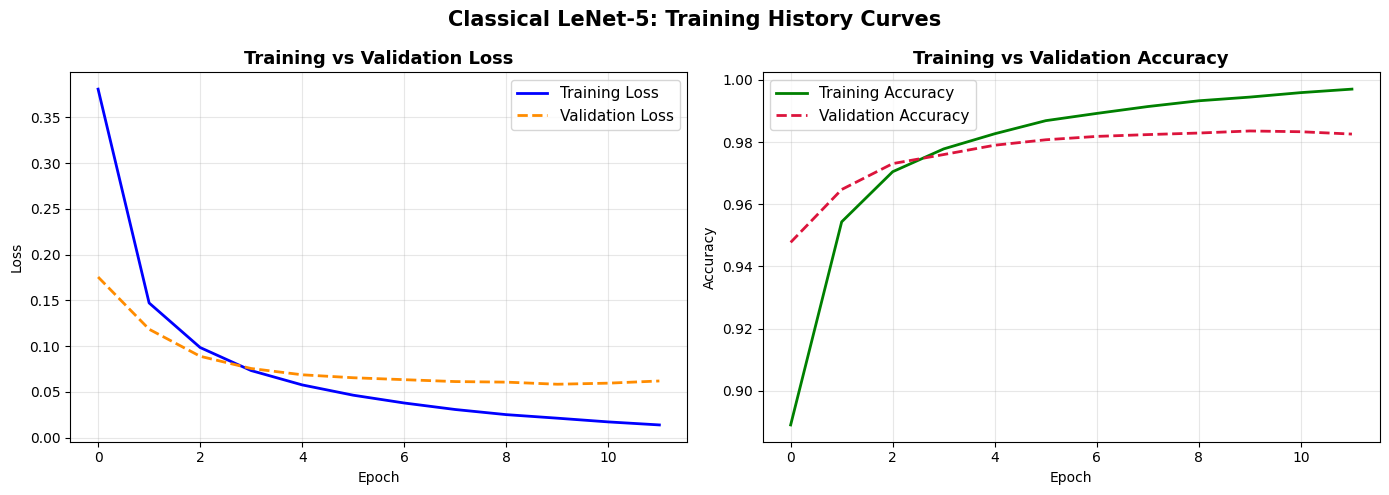

In [10]:
# ============================================================
# STEP 7: Loss aur Accuracy Plots
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Loss Plot
axes[0].plot(history_classic.history['loss'], label='Training Loss', color='blue', lw=2)
axes[0].plot(history_classic.history['val_loss'], label='Validation Loss', color='darkorange', lw=2, linestyle='--')
axes[0].set_title('Training vs Validation Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)

# 2. Accuracy Plot
axes[1].plot(history_classic.history['accuracy'], label='Training Accuracy', color='green', lw=2)
axes[1].plot(history_classic.history['val_accuracy'], label='Validation Accuracy', color='crimson', lw=2, linestyle='--')
axes[1].set_title('Training vs Validation Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=11)

plt.suptitle("Classical LeNet-5: Training History Curves", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## 🎯 STEP 8: Test Set Evaluation & Confusion Matrix

Ab model ko 10,000 unseen test images par evaluate karenge:
- **Test Accuracy & Loss** calculate karenge.
- **Confusion Matrix**: Yeh heatmap dikhayega ki model kaun se digits mein confuse ho raha hai (jaise digit 4 ko 9 samajhna, ya 7 ko 1).
- **Classification Report**: Har digit ke liye Precision, Recall, aur F1-Score check karenge.

📊 Test Loss:     0.0521
🎯 Test Accuracy: 98.40%
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step
=== Classification Report ===
              precision    recall  f1-score   support

           0     0.9868    0.9898    0.9883       980
           1     0.9929    0.9912    0.9921      1135
           2     0.9893    0.9855    0.9874      1032
           3     0.9727    0.9871    0.9799      1010
           4     0.9837    0.9857    0.9847       982
           5     0.9932    0.9787    0.9859       892
           6     0.9823    0.9875    0.9849       958
           7     0.9823    0.9737    0.9780      1028
           8     0.9815    0.9815    0.9815       974
           9     0.9753    0.9782    0.9767      1009

    accuracy                         0.9840     10000
   macro avg     0.9840    0.9839    0.9839     10000
weighted avg     0.9840    0.9840    0.9840     10000



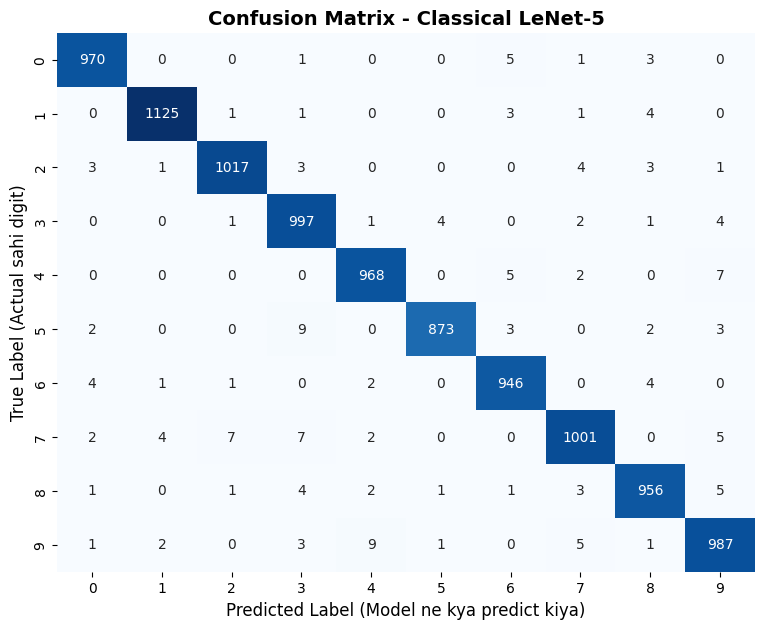

In [12]:
# ============================================================
# STEP 8: Test Set Evaluation & Detailed Metrics
# ============================================================

from sklearn.metrics import classification_report, confusion_matrix

# Test set par evaluate karna
test_loss, test_acc = model_classic.evaluate(X_test_padded, y_test, verbose=0)
print(f"📊 Test Loss:     {test_loss:.4f}")
print(f"🎯 Test Accuracy: {test_acc * 100:.2f}%")

# Model se predictions generate karna
y_pred_probs = model_classic.predict(X_test_padded)
y_pred = np.argmax(y_pred_probs, axis=1)

# Classification Report
print("=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=4))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix - Classical LeNet-5', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label (Model ne kya predict kiya)', fontsize=12)
plt.ylabel('True Label (Actual sahi digit)', fontsize=12)
plt.show()


## 🔍 STEP 9: Test Images par Visual Predictions

Aaiye test set se random images pick karke dekhte hain ki model kitna confident hai.
- **Green Title**: Sahi Prediction ($\\text{True} == \\text{Pred}$)
- **Red Title**: Galat Prediction ($\\text{True} \\neq \\text{Pred}$)

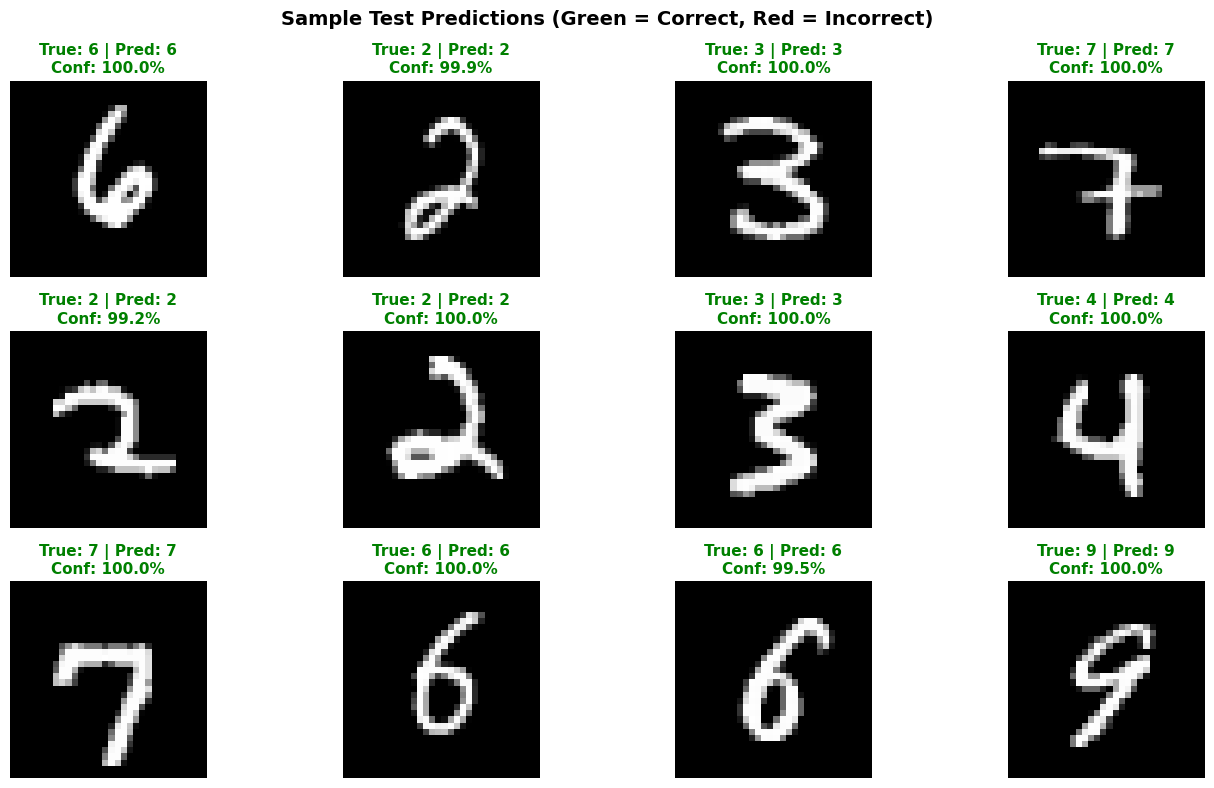

In [13]:
# ============================================================
# STEP 9: Random Test Images par Predictions Visualise Karna
# ============================================================

random_indices = np.random.choice(len(X_test_padded), size=12, replace=False)

plt.figure(figsize=(14, 8))
for i, idx in enumerate(random_indices):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test_padded[idx].squeeze(), cmap='gray')

    true_label = y_test[idx]
    predicted_label = y_pred[idx]
    confidence = y_pred_probs[idx][predicted_label] * 100

    is_correct = (true_label == predicted_label)
    title_color = 'green' if is_correct else 'red'

    plt.title(f"True: {true_label} | Pred: {predicted_label}\nConf: {confidence:.1f}%",
              color=title_color, fontsize=11, fontweight='bold')
    plt.axis('off')

plt.suptitle("Sample Test Predictions (Green = Correct, Red = Incorrect)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 🚀 STEP 10: Modernized LeNet-5 (ReLU + MaxPooling + In-built Padding)

### ❓ Classical vs Modern LeNet-5 me kya farq hai?

1. **Activation Function**:
   - *Classical (1998)*: `Tanh` activation use hoti thi. Problem yeh thi ki Tanh mein saturation aur **vanishing gradients** hote hain jab network deep ho.
   - *Modern*: `ReLU` (Rectified Linear Unit) standard ban chuki hai kyunki yeh vanishing gradient ko khatam karti hai aur training 5-6x fast ho jaati hai.
2. **Subsampling / Pooling**:
   - *Classical*: `AveragePooling2D` use hoti thi jo values ka average leti hai, jisse sharp edges blur ho jaati hain.
   - *Modern*: `MaxPooling2D` use hoti hai jo dominant/strongest features (edges, corners) ko capture karti hai.
3. **Regularization (Dropout)**:
   - Modern architectures mein dense layers ke beech `Dropout` add kiya jata hai taaki overfitting prevent ho.
4. **In-built Padding**:
   - Preprocessing mein manual padding karne ki jagah hum Keras ki `ZeroPadding2D((2, 2))` layer direct model ke start me add kar sakte hain, taaki raw `(28, 28, 1)` images directly input ho sakein!

In [14]:
# ============================================================
# STEP 10: Modern LeNet-5 Architecture
# ============================================================

def build_lenet5_modern(input_shape=(28, 28, 1), num_classes=10):
    """
    Modern LeNet-5 Architecture:
    - Input: Direct 28x28x1 image
    - ZeroPadding2D layer: (28, 28) -> (32, 32)
    - Activations: 'relu'
    - Subsampling: 'MaxPooling2D'
    - Regularization: Dropout
    """
    model = models.Sequential([
        # 1. In-built ZeroPadding layer (28x28 -> 32x32)
        layers.ZeroPadding2D(padding=((2, 2), (2, 2)), input_shape=input_shape, name='Input_ZeroPadding'),

        # 2. C1: 6 filters of 5x5 + ReLU
        layers.Conv2D(filters=6, kernel_size=(5, 5), strides=(1, 1),
                      activation='relu', padding='valid', name='C1_Conv_ReLU'),

        # 3. S2: MaxPooling2D
        layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name='S2_MaxPool'),

        # 4. C3: 16 filters of 5x5 + ReLU
        layers.Conv2D(filters=16, kernel_size=(5, 5), strides=(1, 1),
                      activation='relu', padding='valid', name='C3_Conv_ReLU'),

        # 5. S4: MaxPooling2D
        layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name='S4_MaxPool'),

        # 6. C5: 120 filters of 5x5 + ReLU
        layers.Conv2D(filters=120, kernel_size=(5, 5), strides=(1, 1),
                      activation='relu', padding='valid', name='C5_Conv_ReLU'),

        # 7. Flatten
        layers.Flatten(name='Flatten'),

        # 8. F6: Dense 84 + ReLU
        layers.Dense(units=84, activation='relu', name='F6_Dense_ReLU'),

        # 9. Dropout (Overfitting prevent karne ke liye 30% units randomly drop karna)
        layers.Dropout(0.3, name='Dropout_0.3'),

        # 10. Output Layer
        layers.Dense(units=num_classes, activation='softmax', name='Output_Layer')
    ], name="Modern_LeNet_5")

    return model

model_modern = build_lenet5_modern()
model_modern.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/zero_padding2d.py:72: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "Modern_LeNet_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_ZeroPadding               │ (None, 32, 32, 1)      │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C1_Conv_ReLU (Conv2D)           │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2_MaxPool (MaxPooling2D)       │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3_Conv_ReLU (Conv2D)           │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4_MaxPool (MaxPooling2D)       │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5_Conv_ReLU (Conv2D)           │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6_Dense_ReLU (Dense)           │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_0.3 (Dropout)           │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# ============================================================
# STEP 10.1: Modern LeNet-5 ko Train Karna
# ============================================================

model_modern.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Yahan hum raw X_train (28, 28, 1) pass kar rahe hain kyunki model khud pad kar leta hai!
history_modern = model_modern.fit(
    X_train, y_train,
    batch_size=128,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# Test Evaluation
test_loss_mod, test_acc_mod = model_modern.evaluate(X_test, y_test, verbose=0)
print(f"\n🚀 Modern LeNet-5 Test Accuracy:  {test_acc_mod * 100:.2f}% (Loss: {test_loss_mod:.4f})")
print(f"🏛️ Classical LeNet-5 Test Accuracy: {test_acc * 100:.2f}% (Loss: {test_loss:.4f})")


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 30s 75ms/step - accuracy: 0.8589 - loss: 0.4510 - val_accuracy: 0.9641 - val_loss: 0.1139
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 28s 74ms/step - accuracy: 0.9625 - loss: 0.1277 - val_accuracy: 0.9684 - val_loss: 0.0978
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 74ms/step - accuracy: 0.9724 - loss: 0.0897 - val_accuracy: 0.9762 - val_loss: 0.0766
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.

🚀 Modern LeNet-5 Test Accuracy:  96.51% (Loss: 0.1065)
🏛️ Classical LeNet-5 Test Accuracy: 98.40% (Loss: 0.0521)


## 💡 Interview Questions & Key Insights (In Hinglish)

Jab machine learning ya deep learning interviews mein LeNet-5 ke baare mein pucha jata hai, toh yeh questions aksar aate hain:

### ❓ Q1: MNIST 28x28 size ki hai, toh LeNet-5 mein 32x32 input kyun diya jata hai?
> **Answer**: Original paper mein LeCun ne 32x32 size use kiya tha taaki digits ke corners aur boundary features (strokes, loops) edge effects ki wajah se cut na hon. Saath hi, 5x5 filters ke baad consecutive pooling karte hue C5 layer ka feature map exactly $1 \times 1$ banta hai ($5 \times 5 \rightarrow 1 \times 1$). Agar 28x28 denge toh valid padding ke sath shape mismatch hoga.

### ❓ Q2: Modern CNNs mein Tanh ki jagah ReLU aur AveragePooling ki jagah MaxPooling kyun prefer karte hain?
> **Answer**:
> - **Tanh vs ReLU**: Tanh values ko $(-1, 1)$ mein squish karta hai. Jab inputs bade hote hain, toh derivative almost $0$ ho jata hai (Vanishing Gradient Problem). ReLU ($max(0, x)$) positive inputs ke liye constant derivative ($1$) rakhta hai, jisse deeper networks fast train hote hain.
> - **AveragePooling vs MaxPooling**: Average pooling pixel values ka mean nikaalti hai, jisse contrast aur sharp edges smooth ho jaati hain. MaxPooling sabse prominent feature (jaise dark edge ya strong stroke) ko preserve karta hai.

### ❓ Q3: LeNet-5 mein total parameters kitne hain aur calculation kaise hoti hai?
> **Answer**: LeNet-5 mein approximately **61,706** trainable parameters hote hain. Iska formula hota hai:
> $$\text{Conv Params} = (\text{kernel\_w} \times \text{kernel\_h} \times \text{input\_channels} + 1) \times \text{num\_filters}$$
> $$\text{Dense Params} = (\text{inputs} + 1) \times \text{neurons}$$

---

## 🎯 Final Summary & Takeaways

1. **Pioneering Architecture**: LeNet-5 ne CNNs ka blueprint taiyar kiya: `Conv -> Pool -> Conv -> Pool -> FC -> Output`.
2. **Feature Hierarchy**: Initial layers low-level features (edges, curves) learn karti hain, aur baad ki layers high-level digit shapes capture karti hain.
3. **High Accuracy**: Sirf 61K parameters ke sath yeh model MNIST dataset par **98.5% - 99%+ accuracy** easily achieve kar leta hai!
4. **Modern Upgrades**: ReLU, MaxPooling, aur Dropout add karne se model aur zyada robust, fast, aur accurate ban jata hai.
